# 04 - An overview of the provided py4radiation tables

This tutorial shows how to load and inspect the heating/cooling and ion-fraction tables provided with your `py4radiation` installation.

We present these models in our paper D. Villarruel-Yanez, W. E. Banda-Barragan & B. Casavecchia, (submitted to OJAp).

| model name | SED | Distance | Star-Formation Rate |
|:-|:-|:-:|:-:|
| `metagalactic` | Haardt & Madau (2012) | - | - |
| `starburst-5kpc` | Starburst99 (Leitherer et al., 1999) Figure 8b | $5\,{\rm kpc}$ | $1\,{\rm M}_{\odot}\,{\rm yr}^{-1}$ |
| `starburst-1kpc` | Starburst99 (Leitherer et al., 1999) Figure 8b | $1\,{\rm kpc}$ | $1\,{\rm M}_{\odot}\,{\rm yr}^{-1}$ |

Our tables span a physical grid of $10^{-9}\leq n_{\rm H}\leq 10^4\;{\rm cm}^{-3}$ and $10^{1}\leq T \leq 10^{9}\;{\rm K}$. There are two available resolutions:

1. `hr` (high resolution) : 105 points for $n_{\rm H}$ and 321 points for $T$.
2. `lr` (low resolution) : 27 points for $n_{\rm H}$ and 81 points for $T$.

**Important notes:**

- Our heating/cooling coefficient tables are normalised by $n_{\rm H}^2$. They are expressed in ${\rm erg}\,{\rm cm}^{3}\,{\rm s}^{-1}$.
- The ion-fractions are expressed in logarithmic scale. The redshift value is duplicated, it is not intended as a cosmological calculation, but for compatibility with analysis tools such as yt (Turk et al., 2011) and Trident (Hummels et al. 2017).

In [1]:
# Load packages
import requests
from pathlib import Path
from tqdm.auto import tqdm

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, MultipleLocator

In [2]:
# Set working directories
TABLES_DIR = (Path.cwd() / "tables")
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Fetch data release (v1.0)
url = "https://api.github.com/repos/cPhysPlus/heating-cooling-ion-tables/releases/tags/v1.0"
response = requests.get(url, timeout=30)
response.raise_for_status()

assets = response.json()["assets"]

to_download = [
    asset for asset in assets
    if not (TABLES_DIR / asset["name"]).exists()
    or (TABLES_DIR / asset["name"]).stat().st_size != asset["size"]
]

total_size = sum(asset["size"] for asset in to_download)

print(f"Release assets: {len(assets)}")
print(f"Already downloaded: {len(assets) - len(to_download)}")
print(f"Remaining: {len(to_download)} ({total_size / 1024**2:1f} MB)")

with tqdm(total=total_size, unit="B", unit_scale=True, unit_divisor=1024, desc="Downloading") as pbar:

    for asset in to_download:
        path = TABLES_DIR / asset["name"]
        tmp_path = path.with_name(path.name + ".part")

        pbar.set_postfix_str(asset["name"])

        with requests.get(asset["browser_download_url"], stream=True, timeout=120) as r:
            r.raise_for_status()

            with tmp_path.open("wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        pbar.update(len(chunk))

        if tmp_path.stat().st_size != asset["size"]:
            raise IOError(f"Incomplete download: {asset['name']}")

        tmp_path.replace(path)
        tqdm.write(f"DOWNLOADED {asset['name']}")

print("\nAll tables downloaded!")

Release assets: 12
Already downloaded: 12
Remaining: 0 (0.000000 MB)


Downloading: 0.00B [00:00, ?B/s]


All tables downloaded!


## 1. Cooling tables

In [3]:
def heatcool(file, nval):
    """
    Small helper function to read a heating/cooling table and return the temperature grid
    and heating/cooling coefficients for a given number density value

    Parameters
    ----------
    file : str
        Path to the cooling/heating table file.
    nval : float
        Number density value to select a subset of the tables.

    Returns
    -------
    numpy.ndarray
        Array with Temperature, Heating and Cooling coefficients.
    """
    data = pd.read_csv(file, sep=r'\s+')
    df = data[data.iloc[:, 0] == nval].to_numpy().T
    return df[1:]

In [4]:
# Plotting setup

density_values = [1.0, 0.01, 0.001]
linestyles = ["-", "--", "-."]

heat_line = Line2D([], [], color="red", linewidth=1, linestyle='-', label=r'Heating ($\Gamma$)')
cool_line = Line2D([], [], color="blue", linewidth=1, linestyle='-', label=r'Cooling ($\Lambda$)')

label1    = Line2D([], [], color="black", linewidth=1, linestyle=linestyles[0], label=r"$1$ cm$^{-3}$")
label001  = Line2D([], [], color="black", linewidth=1, linestyle=linestyles[1], label=r"$0.01$ cm$^{-3}$")
label0001 = Line2D([], [], color="black", linewidth=1, linestyle=linestyles[2], label=r"$0.001$ cm$^{-3}$")

In [5]:
# Helper function for plotting

def hc_plot(fig, axs, model, density_values):
    table = f"{model}_cooltable"
    m = np.array([heatcool(TABLES_DIR / f"{table}_hr.dat", i) for i in density_values])
    m_lr = np.array([heatcool(TABLES_DIR / f"{table}_lr.dat", i) for i in density_values])

    for j in range(len(density_values)):
        axs[0].loglog(m[j][0], m[j][1], color="red",  linestyle=linestyles[j])
        axs[0].loglog(m[j][0], m[j][2], color="blue", linestyle=linestyles[j])
        
        axs[1].loglog(m_lr[j][0], m_lr[j][1], color="red",  linestyle=linestyles[j])
        axs[1].loglog(m_lr[j][0], m_lr[j][2], color="blue", linestyle=linestyles[j])

    axs[0].set_title("high resolution", pad=15)
    axs[1].set_title("low resolution", pad=15)
    
    for k in range(2):
        axs[k].set_box_aspect(1)
        axs[k].set_xlabel(r"${\rm T}\ [{\rm K}]$", labelpad=10)
        
    axs[0].set_ylabel(r"Coefficient [${\rm erg}\ {\rm cm}^3\ {\rm s}^{-1}$]", labelpad=10)
    
    axs[0].legend(handles=[heat_line, cool_line], handlelength=2, labelspacing=1)
    axs[1].legend(handles=[label1, label001, label0001], handlelength=2, labelspacing=1)
    
    fig.subplots_adjust(wspace=0.1, hspace=0)

### 1.1 `metagalactic`

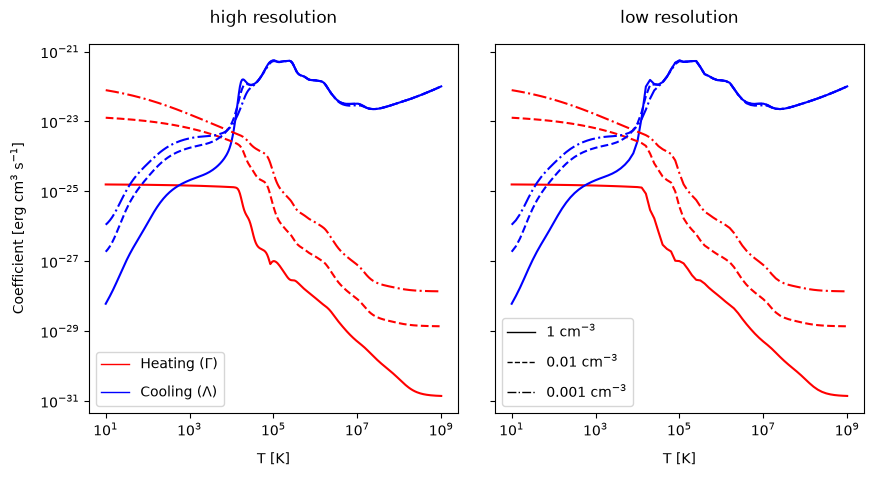

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
hc_plot(fig, axs, "hm2012", density_values)
plt.show()

### 1.2 `starburst-5kpc`

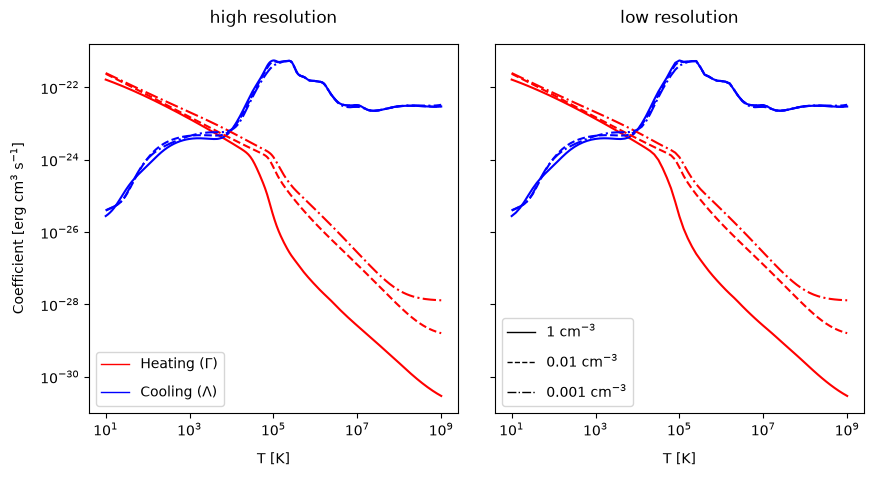

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
hc_plot(fig, axs, "sb5kpc", density_values)
plt.show()

### 1.3 `starburst-1kpc`

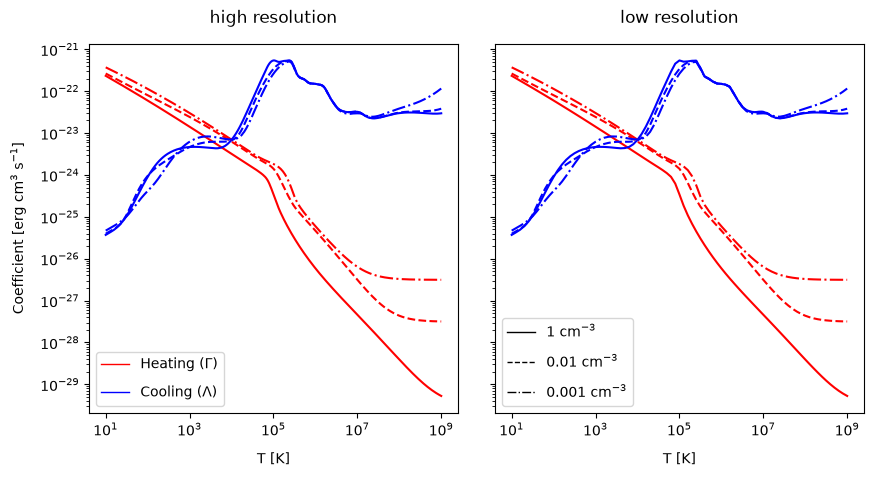

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
hc_plot(fig, axs, "sb1kpc", density_values)
plt.show()

## 2. Ion-fraction tables

In [9]:
# Mesgrid for plotting
def mesh_resolution(resolution, logn_edges=(-9, 4), logT_edges=(1, 9)):
    if resolution == "hr":
        n_points = 105
        T_points = 321
    elif resolution == "lr":
        n_points = 27
        T_points = 81
    else:
        raise ValueError(f"Resolution parameter {resolution} is not valid. Use 'hr' or 'lr'.")

    hden = np.logspace(logn_edges[0], logn_edges[1], n_points)
    temp = np.logspace(logT_edges[0], logT_edges[1], T_points)

    nH, T = np.meshgrid(hden, temp, indexing="ij")

    return np.log10(nH), np.log10(T)

# Average ionisation state in nH-T space
def average_state(fraction_grid):
    states = np.arange(1, fraction_grid.shape[0] + 1)
    return np.tensordot(states, fraction_grid, axes=(0, 0))

# Helper function for plotting
def ib_plot(fig, axs, model, element, levels, cmap, vmin, vmax):
    table = f"{model}_iontable"

    with h5py.File(TABLES_DIR / f"{table}_hr.h5") as f_hr:
        element_hr = 10**f_hr[element][:][:, :, 0, :]

    with h5py.File(TABLES_DIR / f"{table}_lr.h5") as f_lr:
        element_lr = 10**f_lr[element][:][:, :, 0, :]

    element_avstate_hr = average_state(element_hr)
    element_avstate_lr = average_state(element_lr)
    av_state = [element_avstate_hr, element_avstate_lr]

    lognH_hr, logT_hr = mesh_resolution("hr")
    lognH_lr, logT_lr = mesh_resolution("lr")
    lognH = [lognH_hr, lognH_lr]
    logT  = [logT_hr, logT_lr]

    for i in range(2):
        mesh = axs[i].pcolormesh(lognH[i], logT[i], av_state[i], cmap=cmap, vmin=vmin, vmax=vmax)
        axs[i].contour(lognH[i], logT[i], av_state[i], levels=levels, colors="black", linestyles="--", linewidths=0.75)
        axs[i].set_box_aspect(1)
        axs[i].set_xlabel(r'$\log_{10}$(n[${\rm cm}^{-3}$])', labelpad=10)
        if i == 0:
            axs[i].set_ylabel(r'$\log_{10}$(${\rm T}$ [${\rm K}$] )', labelpad=10)

        axs[i].xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
        axs[i].yaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))

    axs[0].set_title("high resolution", pad=15)
    axs[1].set_title("low resolution", pad=15)

    fig.subplots_adjust(wspace=0.15, hspace=0.25)
    cbar = plt.colorbar(mesh, ax=axs.ravel().tolist(), aspect=15, pad=0.02, shrink=0.39)
    cbar.set_label(f'Ionisation state of {element}', labelpad=10)
    cbar.locator = MultipleLocator(1)
    cbar.update_ticks()

Notice we follow the standard spectroscopic notation.

That is, for ${\rm O}\,{\rm I}$ (neutral oxygen), we should read `1` in the colorbar as referring to it.

In summary, ${\rm O}\,{\rm I}\to\text{neutral oxygen}\to\text{stage 1}$.

### 2.1 `metagalactic`

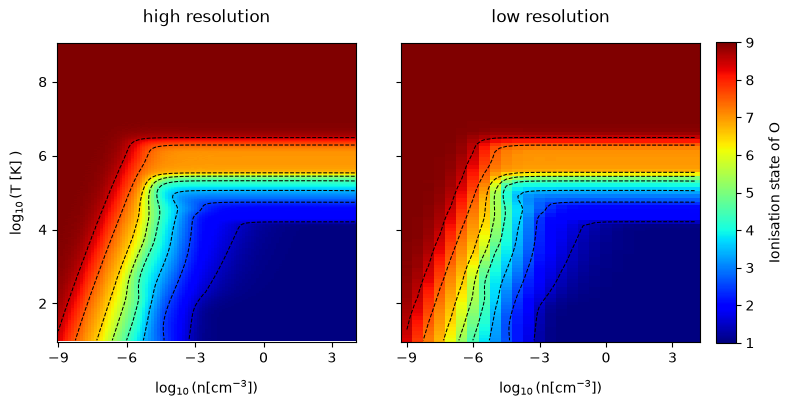

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
ib_plot(fig, axs, "hm2012", "O", np.arange(1.5, 9, 1), "jet", 1, 9)
plt.show()

### 2.2 `starburst-5kpc`

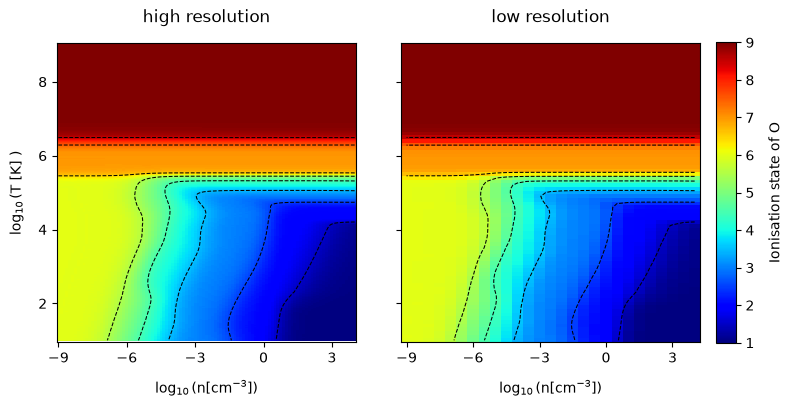

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
ib_plot(fig, axs, "sb5kpc", "O", np.arange(1.5, 9, 1), "jet", 1, 9)
plt.show()

### 2.3 `starburst-1kpc`

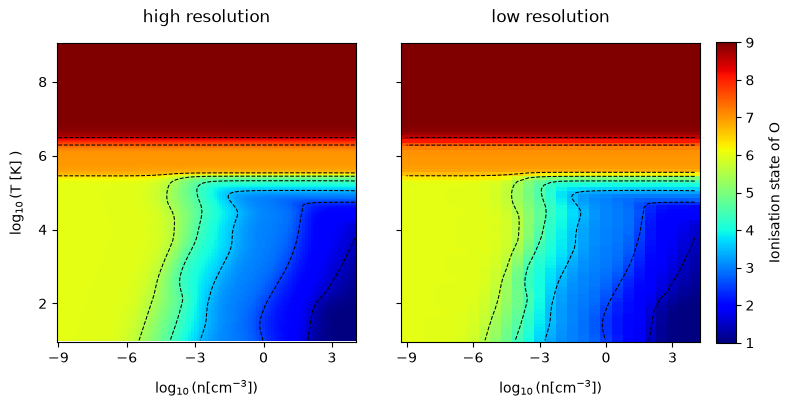

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
ib_plot(fig, axs, "sb1kpc", "O", np.arange(1.5, 9, 1), "jet", 1, 9)
plt.show()